# Projeto Prático 1 – Machine Learning (2026/27)
Previsão do preço (regressão linear) e deteção de anúncios "caros" (regressão logística) com dados do Inside Airbnb, Lisboa (versão de 19 de setembro de 2026).

Este notebook clona o repositório e corre o projeto de ponta a ponta. Para correr: **Runtime > Run all**.
Os modelos (gradiente descendente) estão implementados de raiz em `src/`.

## 1. Preparar o ambiente

In [1]:
REPO_URL = "https://github.com/Andrepf03/ml-projeto1-airbnb.git"
REPO_DIR = REPO_URL.split("/")[-1].replace(".git", "")

import os
if not os.path.exists(REPO_DIR):
    !git clone {REPO_URL}
%cd {REPO_DIR}
!pip install -q numpy pandas scikit-learn matplotlib
!ls data/raw

Cloning into 'ml-projeto1-airbnb'...
remote: Enumerating objects: 83, done.
remote: Counting objects: 100% (83/83), done.
remote: Compressing objects: 100% (81/81), done.
remote: Total 83 (delta 10), reused 0 (delta 0), pack-reused 0 (from 0)
Receiving objects: 100% (83/83), 15.94 MiB | 8.07 MiB/s, done.
Resolving deltas: 100% (10/10), done.
/content/ml-projeto1-airbnb
listings.csv.gz


## 2. Treino e validação (`main.py`)
Prepara os dados (limpeza, features, split 60/20/20), treina a regressão linear e a logística e avalia **na validação**.

In [2]:
!python src/main.py


=== REGRESSÃO LINEAR (preço) ===
taxa=0.1667 | convergiu=True | divergiu=False | épocas=6206
 conjunto    MAE    RMSE    R2
validação 64.772 348.439 0.148

=== REGRESSÃO LOGÍSTICA (caro / não caro) ===
convergiu=True | divergiu=False | épocas=7656
limiar 0.50 (por defeito) vs limiar que maximiza o F1 na validação: 0.25
 conjunto  limiar  accuracy  baseline  precision  recall    F1   AUC  PR-AUC  log_loss   VN  FP  FN  VP
validação    0.50     0.863     0.803      0.728   0.483 0.581 0.873   0.689     0.328 3474 161 461 431
validação    0.25     0.828     0.803      0.547   0.743 0.631 0.873   0.689     0.328 3087 548 229 663

Precision / recall / F1 para vários limiares (validação):
 limiar  precision  recall    F1  accuracy  % previstos caro
   0.10      0.379   0.904 0.534     0.690             0.469
   0.15      0.439   0.852 0.580     0.757             0.382
   0.20      0.491   0.793 0.606     0.797             0.318
   0.25      0.547   0.743 0.631     0.828             0.268
  

## 3. Estudos com k-fold (`experiments.py`)
Compara imputação, tratamento de outliers, estadia mínima e variáveis extra, com 5 folds e pré-processamento refeito em cada fold (sem leakage).
Pode demorar alguns minutos.

In [3]:
!python src/experiments.py --estudo todos

Dados de desenvolvimento (treino+validação): 18108 anúncios | 5 folds

=== REGRESSÃO (preço, avaliado em euros) – 5 folds ===
  simples + nada feito (64s)
  simples + capping feito (60s)
  simples + filtrar feito (27s)
  grupos + nada feito (59s)
  grupos + capping feito (60s)
  grupos + filtrar feito (28s)
       estrategia            MAE             RMSE            R2        R2_log  dif MAE vs baseline folds melhores (MAE) convergiu
   simples + nada 64.908 ± 1.934 347.381 ± 18.661 0.172 ± 0.048 0.654 ± 0.018               0.0000                  0/5       5/5
simples + capping 66.234 ± 1.778 355.762 ± 23.909 0.134 ± 0.026 0.643 ± 0.020               1.3262                  0/5       5/5
simples + filtrar 65.642 ± 1.632 353.763 ± 22.124 0.143 ± 0.033 0.637 ± 0.033               0.7341                  0/5       5/5
    grupos + nada 64.954 ± 1.968 347.537 ± 18.688 0.172 ± 0.049 0.653 ± 0.019               0.0469                  2/5       5/5
 grupos + capping 66.288 ± 1.798 355.839 

## 4. Avaliação final no teste (`final_analysis.py`)
O conjunto de teste é usado **uma só vez**, aqui, com os modelos já escolhidos.

In [4]:
!python src/final_analysis.py

ATENÇÃO: a usar o conjunto de TESTE (só deve acontecer no fim do projeto).

Treino final (treino+validação): 18108 anúncios | Teste: 4528 anúncios

A treinar os modelos finais...
  regressão: taxa=0.1667 | convergiu=True | épocas=5764
  logística: convergiu=True | divergiu=False | épocas=8010

=== REGRESSÃO LINEAR: avaliação no teste ===
  MAE   RMSE    R2  R2_log  MAE_baseline_mediana  n_teste
64.32 335.26 0.132   0.651                100.19     4528

Coeficientes da regressão (log-preço; efeito_% = efeito multiplicativo no preço) – top 20:
                                                               variavel  peso_log  efeito_%                            tipo
                                                  room_type=Shared room    -0.860   -57.678       categoria (vs referência)
                               neighbourhood_cleansed=Cascais e Estoril     0.353    42.337       categoria (vs referência)
                                            property_type=Room in hotel     0.33

## 5. Resultados finais

In [5]:
import pandas as pd
from IPython.display import display

print("Regressão (teste):")
display(pd.read_csv("figures/etapa14_teste_regressao.csv").round(3))
print("Classificação (teste):")
display(pd.read_csv("figures/etapa14_teste_classificacao.csv").round(3))

Regressão (teste):


,MAE,RMSE,R2,R2_log,MAE_baseline_mediana,n_teste
0,64.32,335.26,0.132,0.651,100.19,4528


Classificação (teste):


,limiar,accuracy,baseline,precision,recall,F1,AUC,PR-AUC,log_loss,VN,FP,FN,VP
0,0.50,0.852,0.793,0.724,0.460,0.563,0.873,0.682,0.339,3428,164,505,431
1,0.25,0.820,0.793,0.549,0.716,0.622,0.873,0.682,0.339,3042,550,266,670


## 6. Figuras

etapa2_distribuicao_preco.png


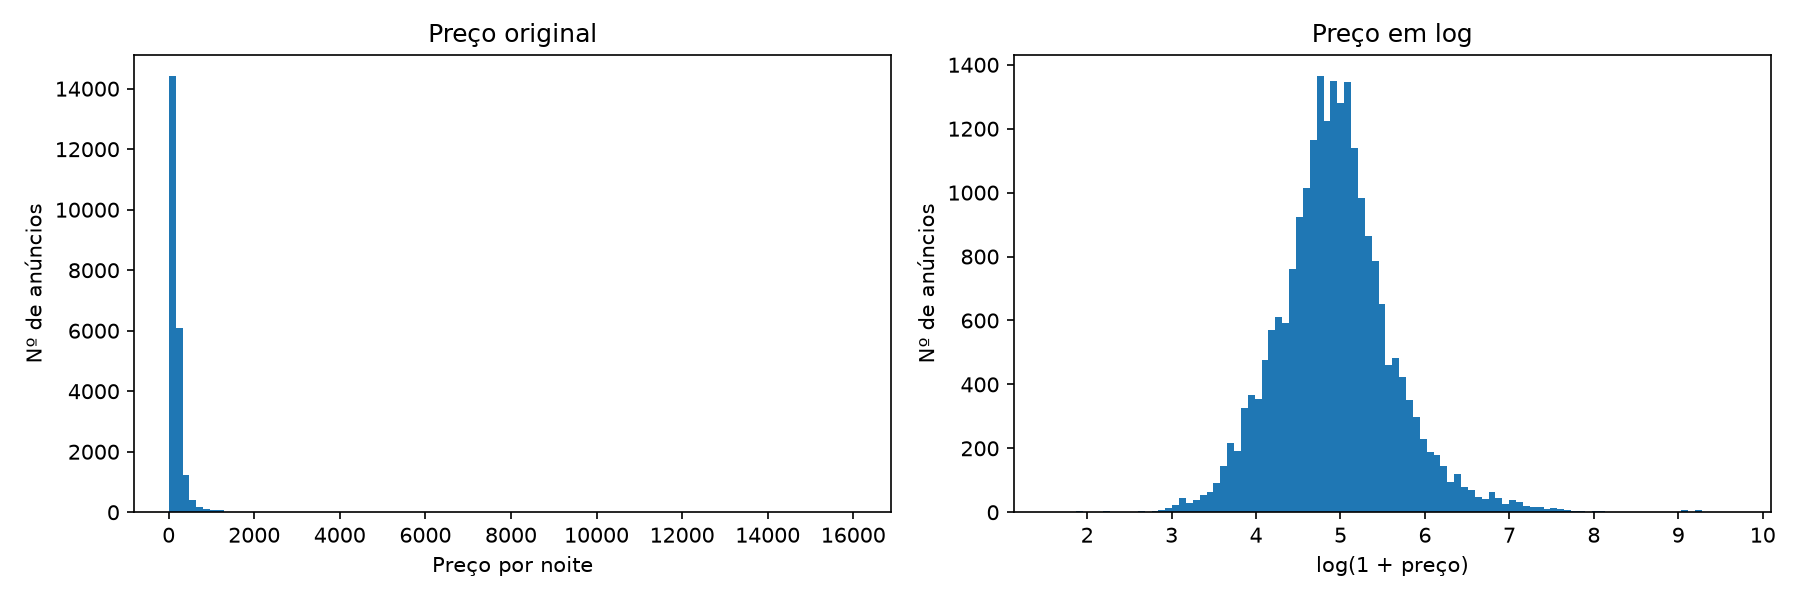

etapa3_mapa_faltas.png


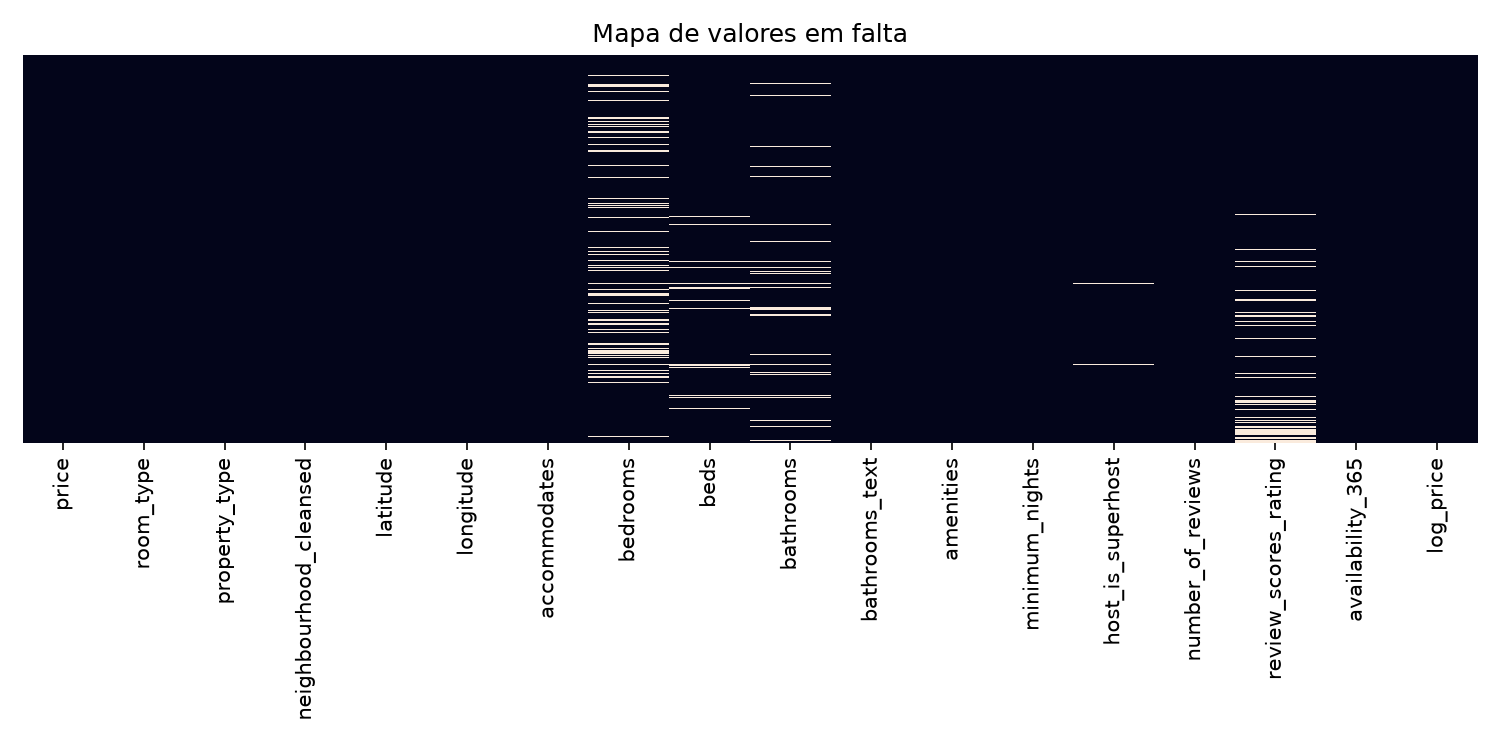

etapa4_outliers.png


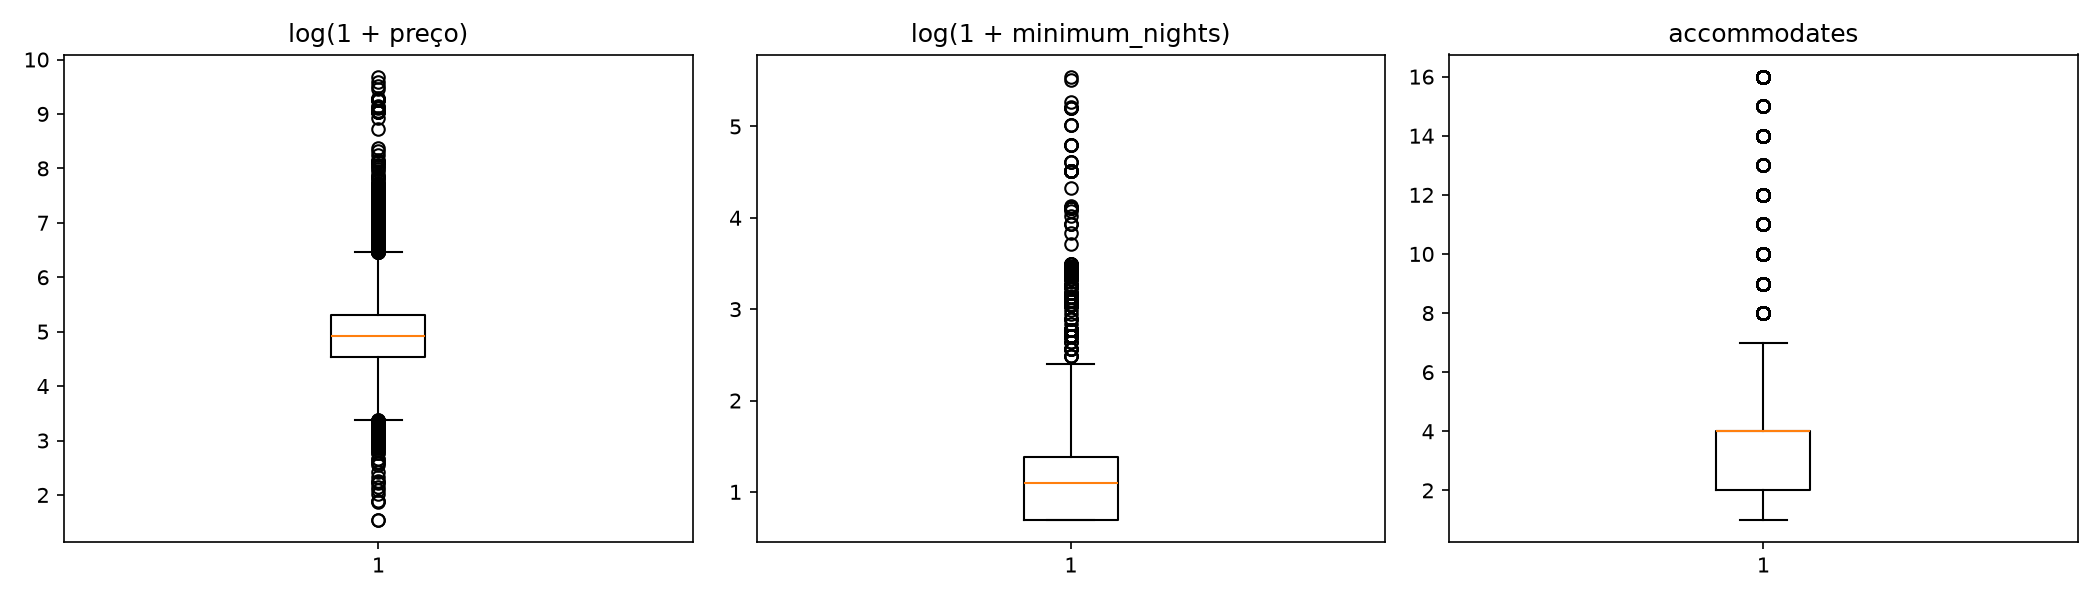

etapa8_convergencia_batch.png


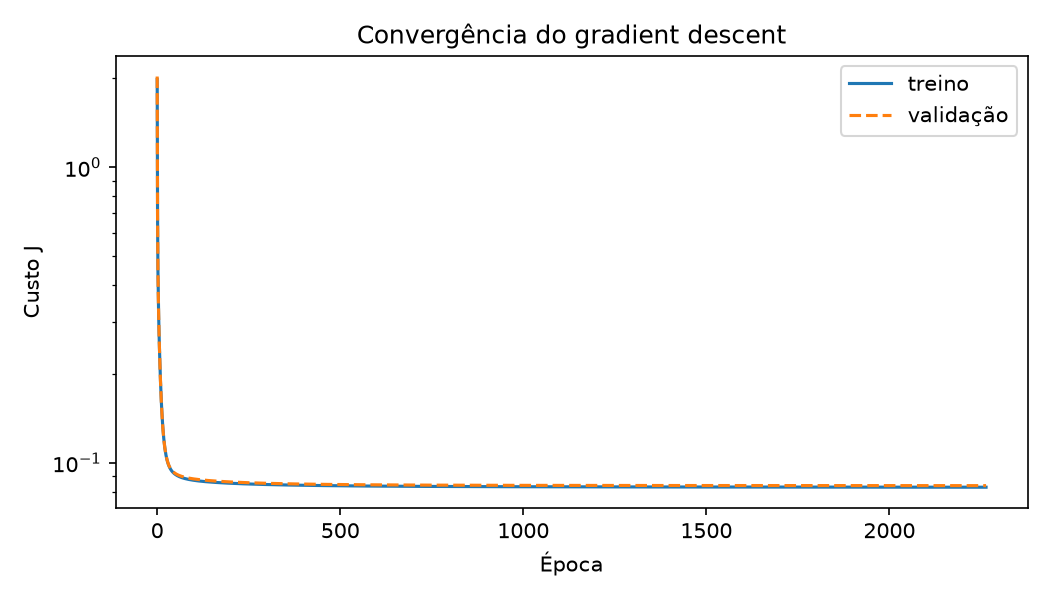

etapa8_convergencia_minibatch.png


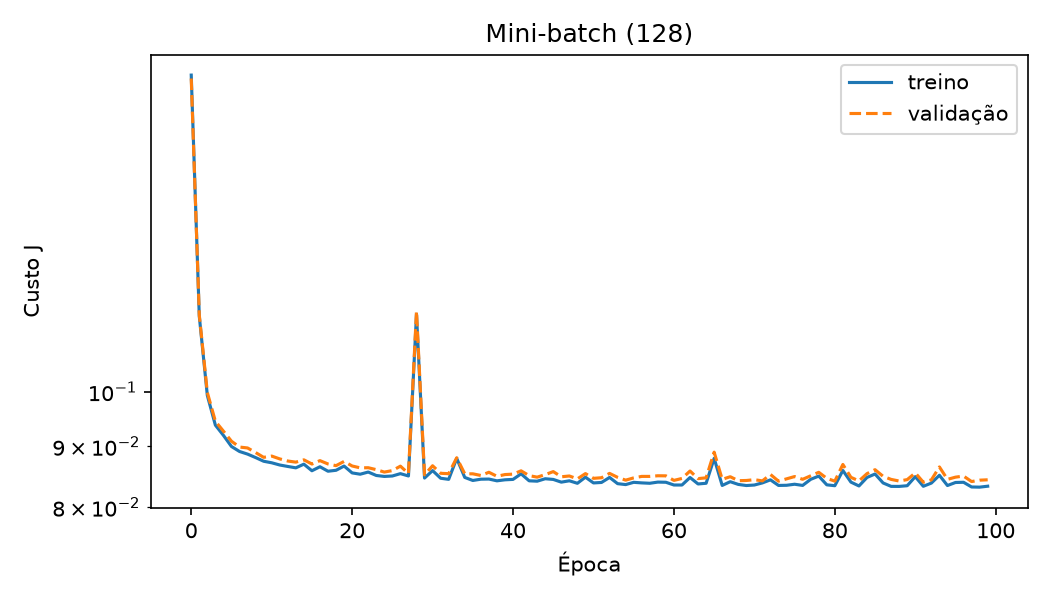

regressao_convergencia.png


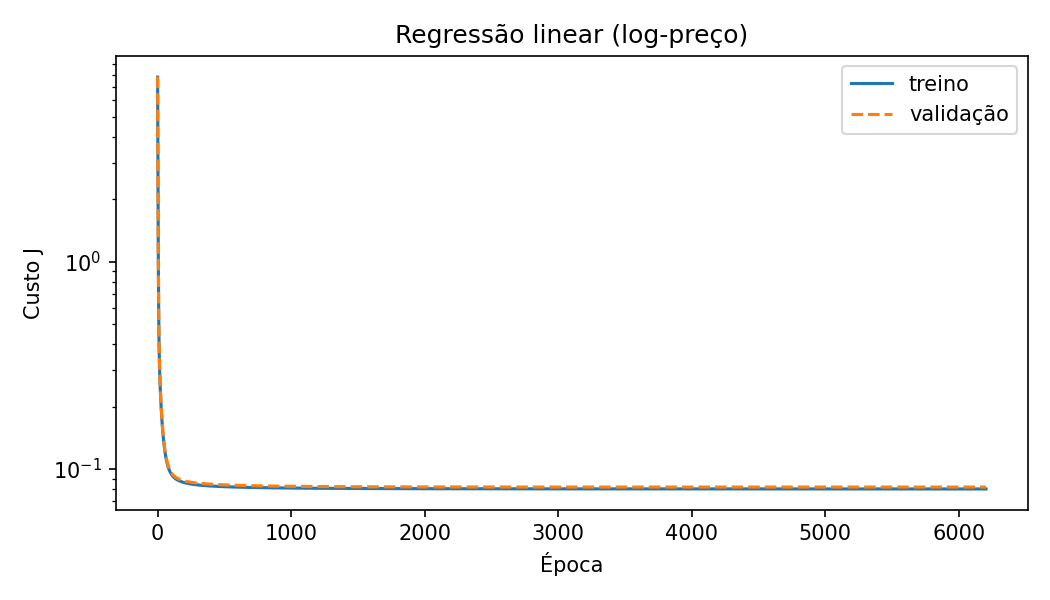

etapa14_residuos.png


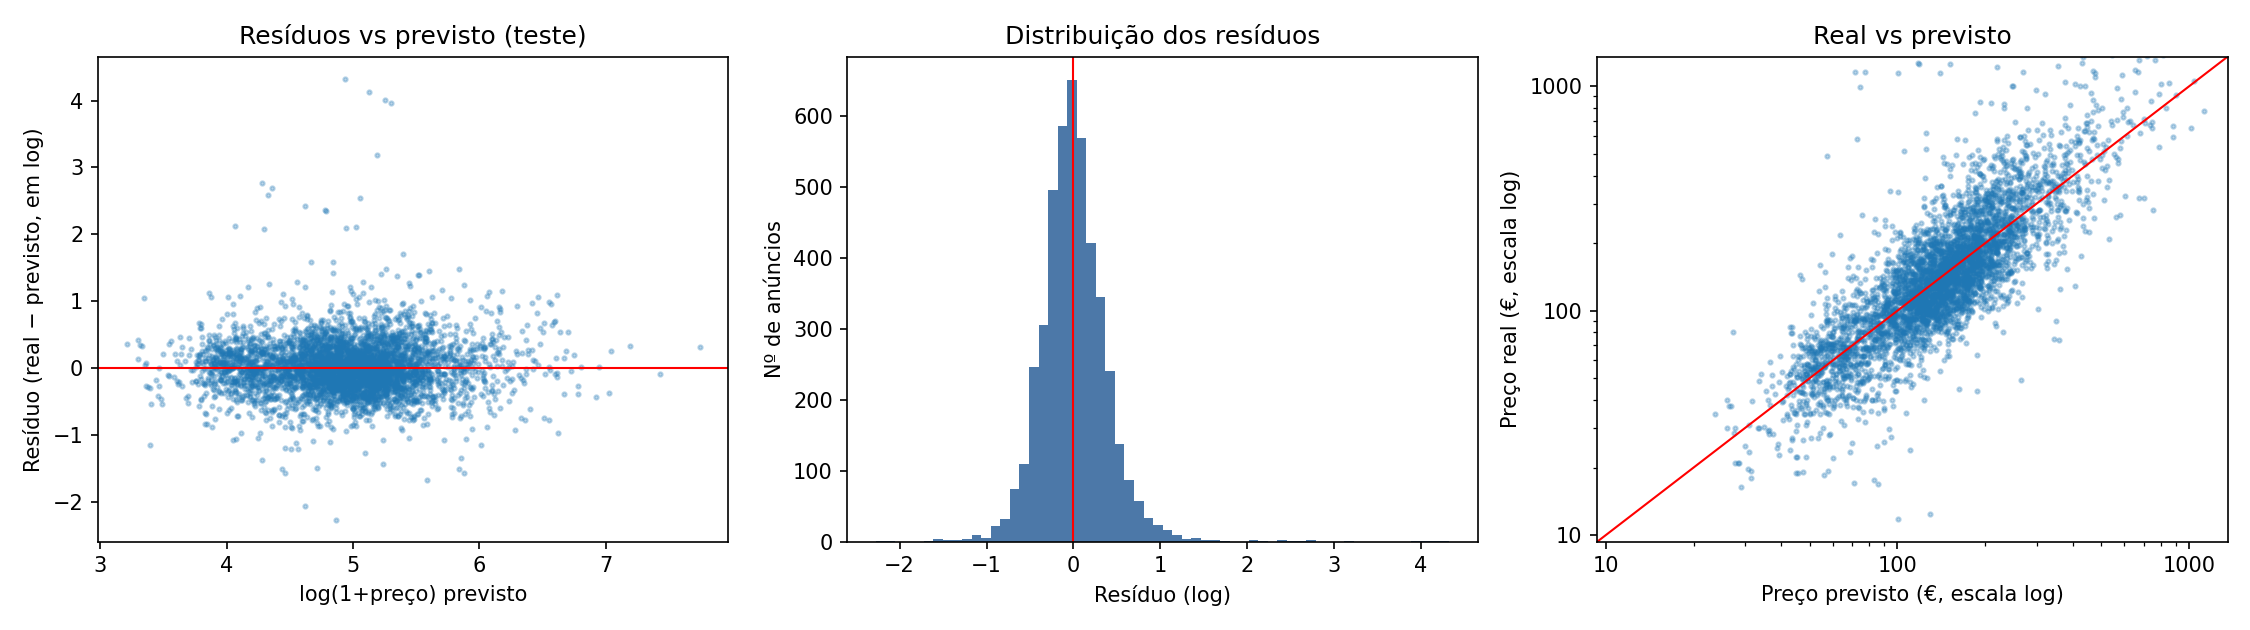

etapa14_erro_grupos.png


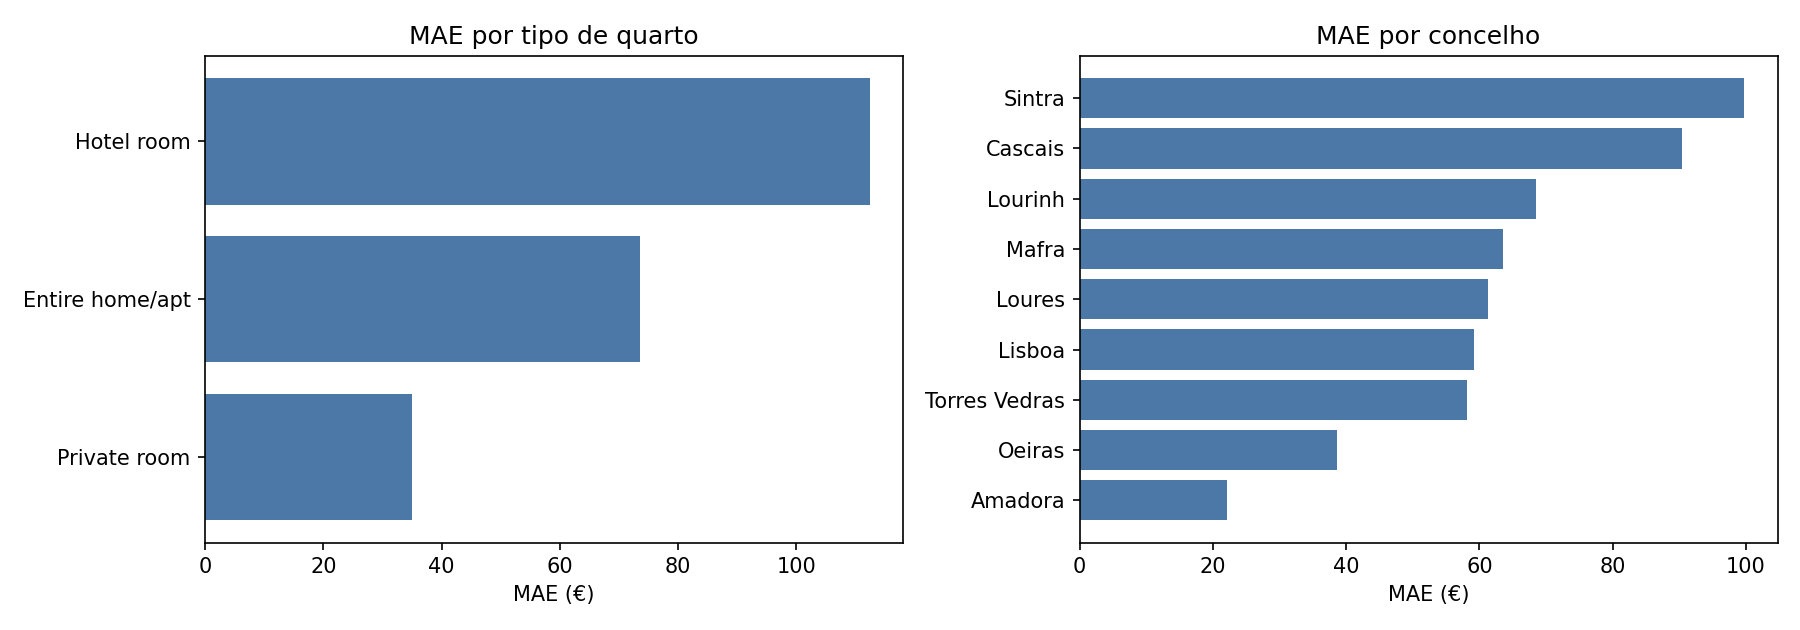

logistica_convergencia.png


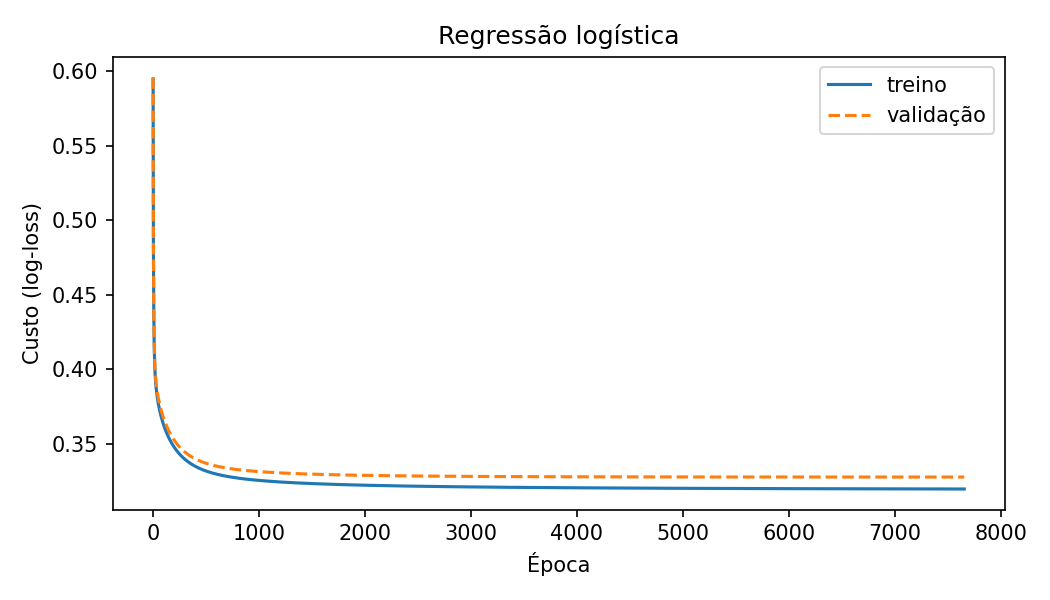

logistica_confusao_limiar_f1.png


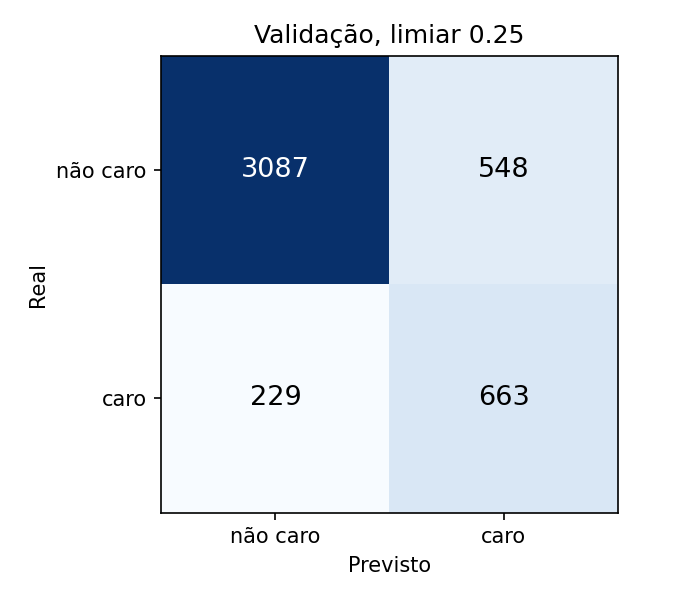

logistica_roc_pr.png


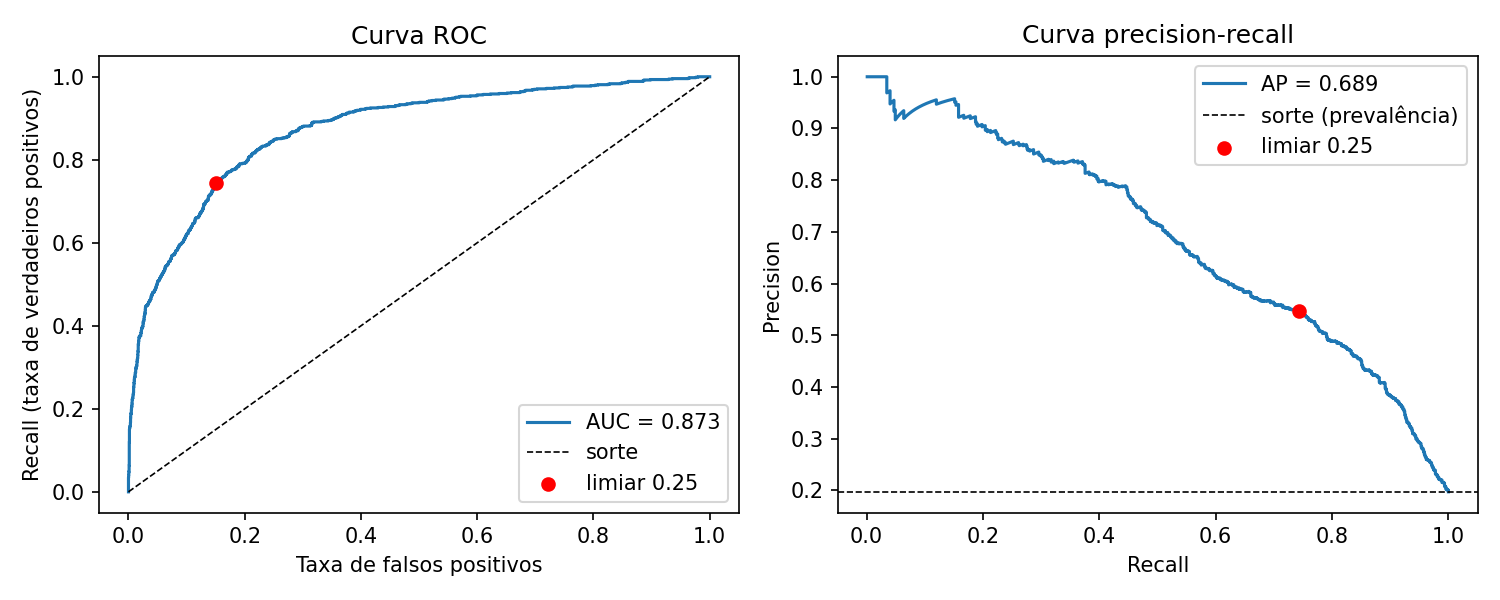

etapa13_regressao_mae.png


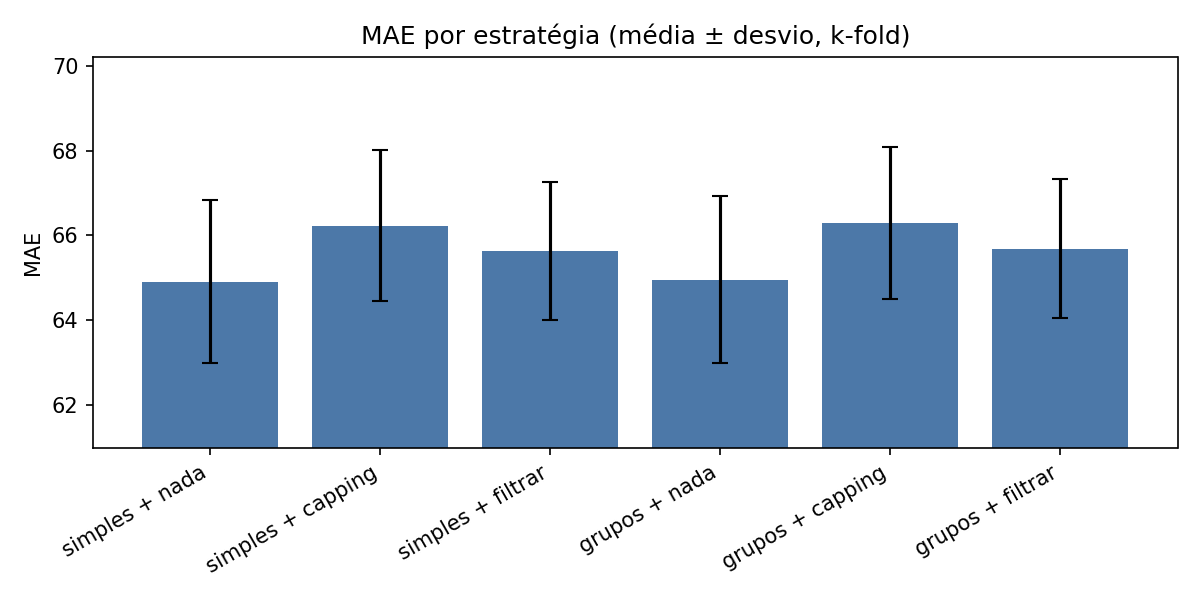

etapa13_classificacao_auc.png


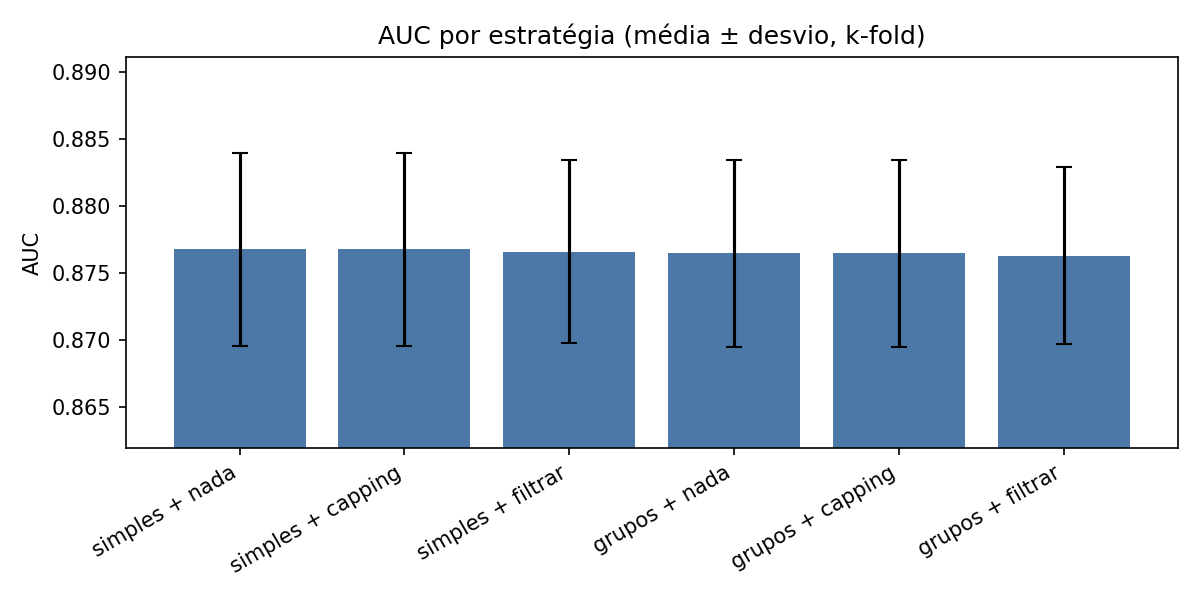

etapa14_confusao_teste.png


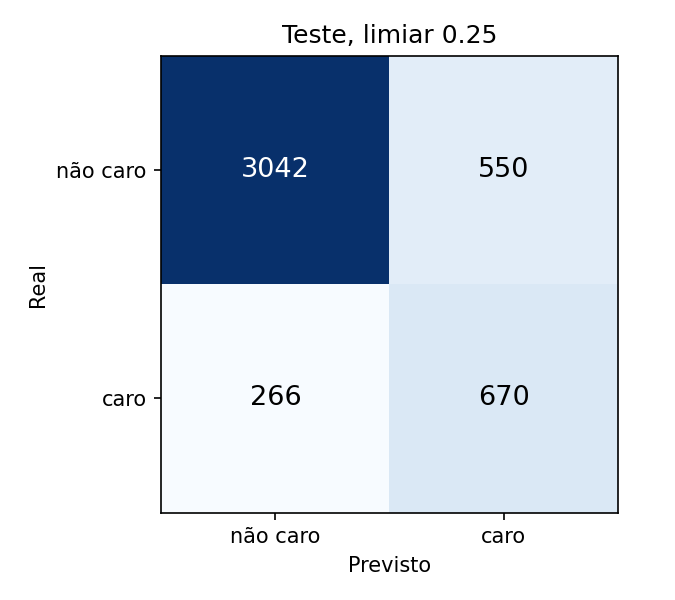

etapa14_roc_pr_teste.png


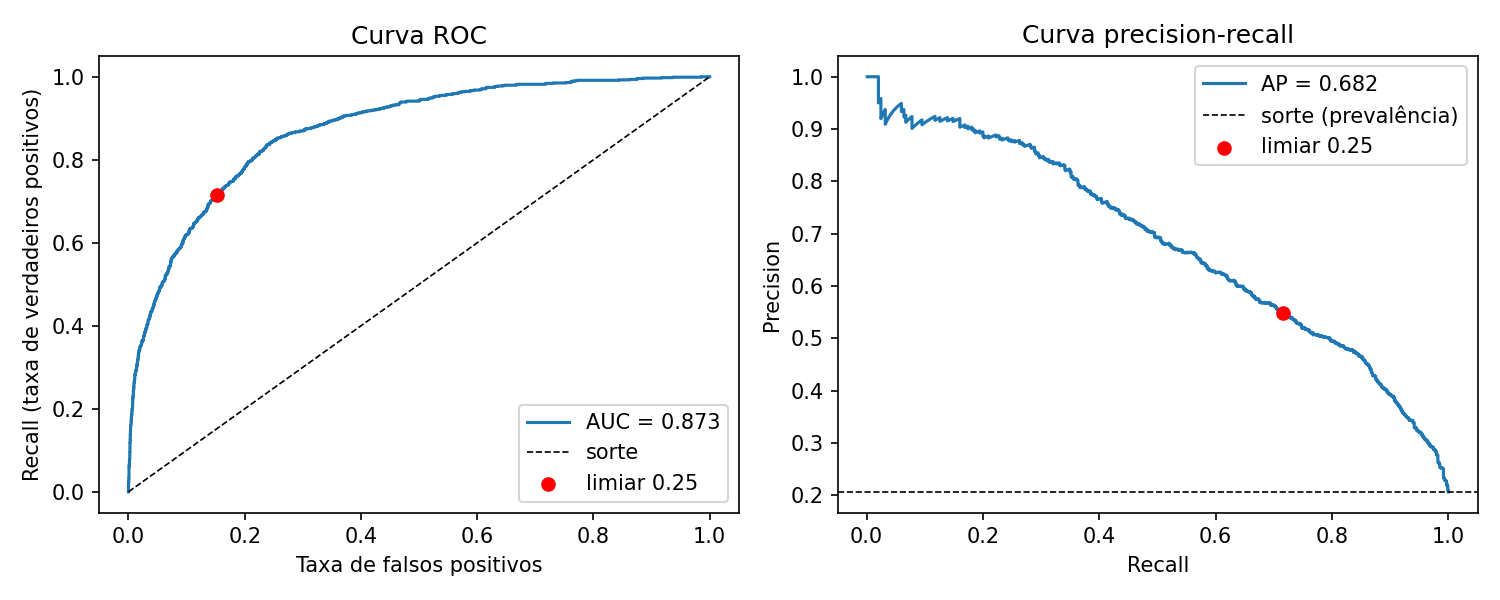

In [6]:
from IPython.display import Image, display
import os

figuras = [
    "etapa2_distribuicao_preco.png", "etapa3_mapa_faltas.png", "etapa4_outliers.png",
    "etapa8_convergencia_batch.png", "etapa8_convergencia_minibatch.png",
    "regressao_convergencia.png", "etapa14_residuos.png", "etapa14_erro_grupos.png",
    "logistica_convergencia.png", "logistica_confusao_limiar_f1.png", "logistica_roc_pr.png",
    "etapa13_regressao_mae.png", "etapa13_classificacao_auc.png",
    "etapa14_confusao_teste.png", "etapa14_roc_pr_teste.png",
]
for f in figuras:
    caminho = os.path.join("figures", f)
    if os.path.exists(caminho):
        print(f)
        display(Image(caminho))
    else:
        print(f"(falta {f} - fazer commit da figura no repositório)")


## 7. Coeficientes (interpretação)
Efeito em % no preço (regressão) e *odds ratio* (logística).

In [7]:
pd.set_option("display.max_rows", 30)
print("Regressão (log-preço) – maiores efeitos:")
r = pd.read_csv("figures/etapa14_coeficientes_regressao.csv")
display(r.reindex(r["peso_log"].abs().sort_values(ascending=False).index).head(15).round(3))
print("Logística – maiores efeitos:")
l = pd.read_csv("figures/etapa14_coeficientes_logistica.csv")
display(l.reindex(l["peso"].abs().sort_values(ascending=False).index).head(15).round(3))

Regressão (log-preço) – maiores efeitos:


,variavel,peso_log,efeito_%,tipo
0,room_type=Shared room,-0.860,-57.678,categoria (vs referência)
1,neighbourhood_cleansed=Cascais e Estoril,0.353,42.337,categoria (vs referência)
2,property_type=Room in hotel,0.334,39.596,categoria (vs referência)
3,banho_partilhado,-0.311,-26.716,0/1
4,property_type=Room in boutique hotel,0.302,35.201,categoria (vs referência)
5,property_type=Entire villa,0.300,35.024,categoria (vs referência)
6,neighbourhood_cleansed=Parque das Naes,0.298,34.726,categoria (vs referência)
7,property_type=Boat,-0.272,-23.843,categoria (vs referência)
8,accommodates,0.263,30.138,numérica (por +1 desvio-padrão)
9,neighbourhood_cleansed=Beato,-0.247,-21.885,categoria (vs referência)


Logística – maiores efeitos:


,variavel,peso,odds_ratio,tipo
0,room_type=Private room,3.076,21.661,categoria (vs referência)
1,room_type=Shared room,2.281,9.786,categoria (vs referência)
2,banho_partilhado,-2.033,0.131,0/1
3,property_type=Room in hotel,2.002,7.401,categoria (vs referência)
4,property_type=Room in boutique hotel,1.491,4.442,categoria (vs referência)
5,neighbourhood_cleansed=Parque das Naes,1.446,4.246,categoria (vs referência)
6,accommodates,1.279,3.594,numérica (por +1 desvio-padrão)
7,neighbourhood_cleansed=Beato,-1.267,0.282,categoria (vs referência)
8,neighbourhood_cleansed=Penha de Frana,-1.246,0.288,categoria (vs referência)
9,property_type=Private room in villa,0.961,2.615,categoria (vs referência)
